# Assignment 6: Deployment, Dashboard, and Data Storytelling Report

## Dataset Transition: From Kaggle to TCGA

In Assignments 3–5, I used a Kaggle lung cancer dataset to develop my initial data analysis and machine learning models. During the modeling process, however, I noticed an unexpected pattern: Stage I and Stage IV patients appeared to have almost identical survival rates (approximately 50%).

This result raised concerns about the dataset's clinical realism. In general, cancer stage is an important prognostic factor, and patients diagnosed at an earlier stage would generally be expected to have better survival outcomes than patients diagnosed at an advanced stage. The Kaggle dataset did not appear to demonstrate this expected relationship. This suggested that the dataset might have limitations for our final objective of building a clinically meaningful survival classification model.

Rather than immediately changing datasets, I investigated whether another dataset would be more suitable. I examined the TCGA PanCancer Atlas Lung Adenocarcinoma (LUAD) dataset using the same Stage-versus-Survival diagnostic approach. The TCGA data showed a more clinically plausible pattern, with Stage I patients generally demonstrating better survival outcomes than Stage IV patients. This provided a stronger reason to use TCGA for the final stage of the project, although the pattern alone does not prove that every record is accurate.

Another important reason for choosing TCGA was its availability of clinical survival information, including Overall Survival (Months) and Overall Survival Status. These variables allowed me to define a more transparent 5-year (60-month) survival classification.

TCGA also introduced an important real-world challenge: some patients were still alive when their follow-up ended. Their final 5-year survival outcome could not be determined from the available data. Instead of incorrectly labeling these patients as "Short-Term," I treated their outcomes as censored and excluded them from the binary classification labels.

**Why I made this change:**

1. To address the limitations of the Kaggle dataset, which did not demonstrate the expected relationship between cancer stage and survival.
2. To use a research dataset with clinical survival time and survival status information.
3. To define a more transparent 60-month survival classification target.
4. To demonstrate how incomplete follow-up and censoring affect real-world clinical data analysis.

Switching datasets does not mean that the earlier work was wasted. Assignments 3–5 provided the foundation in data cleaning, exploratory analysis, feature engineering, and machine learning. Assignment 6 builds on those skills using a dataset that is more suitable for the final survival-classification objective.

Note: TCGA is a research cohort and may not represent the broader lung cancer population. This model is an educational research prototype, not a clinically validated tool, and should not be used to make medical decisions.

## Project: Lung Cancer 5-Year Survival Group Classification (TCGA PanCancer Atlas LUAD)

## Objective
Explore the TCGA lung cancer dataset, define a transparent 60-month outcome, analyze class imbalance, train leakage-safe models, compare a class-weighted baseline with a SMOTE-balanced experiment, and export a deployable model for a Streamlit prototype.

**Important clinical limitation:** This is an educational retrospective classification exercise, not a validated clinical decision-support system. A patient alive with less than 60 months of follow-up has an unknown 5-year outcome (right-censored) and is excluded from the binary training labels rather than incorrectly labelled as Short-Term.

## 1. Setup and data loading

In [22]:
from pathlib import Path
import re, warnings, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (accuracy_score, f1_score, recall_score,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
RANDOM_STATE = 42


DATA_PATH = "../data/lung_cancer_data.csv.csv"
df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (566, 63)


,Study ID,Patient ID,Sample ID,Diagnosis Age,Neoplasm Disease Stage American Joint Committee on Cancer Code,American Joint Committee on Cancer Publication Version Type,Aneuploidy Score,Buffa Hypoxia Score,Cancer Type,TCGA PanCanAtlas Cancer Type Acronym,...,Tumor Break Load,Tissue Prospective Collection Indicator,Tissue Retrospective Collection Indicator,Tissue Source Site,Tissue Source Site Code,TMB (nonsynonymous),Tumor Disease Anatomic Site,Tumor Type,Patient Weight,Winter Hypoxia Score
0,luad_tcga_pan_can_atlas_2018,TCGA-05-4244,TCGA-05-4244-01,70.0,STAGE IV,6TH,17.0,11.0,Non-Small Cell Lung Cancer,LUAD,...,98.0,No,Yes,Indivumed,5,6.400000,Lung,Lung Adenocarcinoma (NOS),NaN,20.0
1,luad_tcga_pan_can_atlas_2018,TCGA-05-4249,TCGA-05-4249-01,67.0,STAGE IB,6TH,24.0,-27.0,Non-Small Cell Lung Cancer,LUAD,...,29.0,No,Yes,Indivumed,5,10.000000,Lung,Lung Adenocarcinoma (NOS),NaN,-26.0
2,luad_tcga_pan_can_atlas_2018,TCGA-05-4250,TCGA-05-4250-01,79.0,STAGE IIIA,6TH,17.0,29.0,Non-Small Cell Lung Cancer,LUAD,...,81.0,No,Yes,Indivumed,5,10.500000,Lung,Lung Adenocarcinoma (NOS),NaN,32.0
3,luad_tcga_pan_can_atlas_2018,TCGA-05-4382,TCGA-05-4382-01,68.0,STAGE IB,6TH,22.0,19.0,Non-Small Cell Lung Cancer,LUAD,...,226.0,No,Yes,Indivumed,5,51.733333,Lung,"Lung Adenocarcinoma, Mixed Subtype",NaN,34.0
4,luad_tcga_pan_can_atlas_2018,TCGA-05-4384,TCGA-05-4384-01,66.0,STAGE IIIA,6TH,1.0,-37.0,Non-Small Cell Lung Cancer,LUAD,...,6.0,No,Yes,Indivumed,5,3.966667,Lung,"Lung Adenocarcinoma, Mixed Subtype",NaN,-24.0


## 2. Data quality and outcome definition
The original dataset has `Overall Survival (Months)` and `Overall Survival Status`. The target is derived from these outcome fields, so **neither field is allowed in the predictors**.

Definition used:
- Short-Term: recorded survival time below 60 months **and** status is `1:DECEASED`.
- Long-Term: recorded survival time is at least 60 months (whether living or deceased at last follow-up).
- Excluded (Censored): Exclude patients recorded as `0:LIVING` with less than 60 months follow-up because their 5-year outcome is not yet known (right-censored).
- Rows missing survival time or survival status are excluded from labelled modelling data.

This is a pragmatic binary label for the assignment, not a substitute for Kaplan–Meier/Cox survival analysis.

In [23]:
# Define column names as variables for easier reference
OS_COL = "Overall Survival (Months)"
STATUS_COL = "Overall Survival Status"
STAGE_COL = "Neoplasm Disease Stage American Joint Committee on Cancer Code"

# Display the initial shape of the dataset and the top 15 columns with the most missing values
print("Original shape:", df.shape)
print("Missing values (top 15):")
display(df.isna().sum().sort_values(ascending=False).head(15).to_frame("missing"))

# Create a copy of the dataframe to avoid modifying the original data
d = df.copy()

# Convert the survival months column to numeric (invalid parsing becomes NaN)
d[OS_COL] = pd.to_numeric(d[OS_COL], errors="coerce")

# Drop rows where either survival time or survival status is missing
d = d.dropna(subset=[OS_COL, STATUS_COL]).copy()

# Function to create the binary target label based on survival months and status
def make_label(row):
    months = row[OS_COL]
    status = str(row[STATUS_COL]).strip().upper()
    # If survival time is 60 months or more, assign "Long-Term"
    if months >= 60:
        return "Long-Term"
     # If survival time is below 60 months and the patient is deceased, assign "Short-Term"
    if status.startswith("1:DECEASED") or "DECEASED" in status:
        return "Short-Term"
    # If patient is still alive with less than 60 months follow-up, return NaN (right-censored/unknown)
    return np.nan  # living with <60 months follow-up: censored/unknown

# Apply the labeling function to each row to create the Survival_Group target column
d["Survival_Group"] = d.apply(make_label, axis=1)

# Count how many patients were excluded due to censoring (still alive but <60 months)
censored_excluded = int(d["Survival_Group"].isna().sum())

# Keep only rows with a valid label (Long-Term or Short-Term) for modeling
model_df = d.dropna(subset=["Survival_Group"]).copy()

# Display dataset sizes: total usable rows, censored rows excluded, and final modeling rows
print("Rows with usable OS + status:", len(d))
print("Censored/unknown under 60 months excluded:", censored_excluded)
print("Labelled modelling rows:", len(model_df))

# Show the distribution of the target variable in the final modeling dataset
display(model_df["Survival_Group"].value_counts().to_frame("count"))
display((model_df["Survival_Group"].value_counts(normalize=True)*100).round(2).to_frame("percent"))

#Define the original column name
STAGE_COL = "Neoplasm Disease Stage American Joint Committee on Cancer Code"

#Function to simplify stage names (e.g., "STAGE IA" -> "Stage I")
def simplify_stage(value):
    if pd.isna(value): return np.nan
    s = str(value).upper().replace(" ", "")
    m = re.search(r"STAGE(IV|III|II|I)", s)
    if not m: return np.nan
    return "Stage " + m.group(1)

# Apply the function to model_df
model_df["Stage_Simplified"] = model_df[STAGE_COL].apply(simplify_stage)

#Verify the column is created
print("Stage_Simplified column created successfully!")
print(model_df["Stage_Simplified"].value_counts(dropna=False))

Original shape: (566, 63)
Missing values (top 15):


,missing
Primary Lymph Node Presentation Assessment,566
Patient Weight,566
Neoplasm Histologic Grade,566
Disease Free (Months),265
Disease Free Status,262
Ethnicity Category,176
Last Communication Contact from Initial Pathologic Diagnosis Date,174
Person Neoplasm Cancer Status,145
New Neoplasm Event Post Initial Therapy Indicator,117
Race Category,117


Rows with usable OS + status: 505
Censored/unknown under 60 months excluded: 281
Labelled modelling rows: 224


,count
Survival_Group,
Short-Term,171
Long-Term,53


,percent
Survival_Group,
Short-Term,76.34
Long-Term,23.66


Stage_Simplified column created successfully!
Stage_Simplified
Stage I      100
Stage II      59
Stage III     49
Stage IV      16
Name: count, dtype: int64


## 3. Stage normalization and exploratory data storytelling
AJCC sub-stages are consolidated into Stage I–IV. Unknown/unmapped values remain missing and are imputed inside the training pipeline.

Stage distribution:


,patients
Stage_Simplified,
Stage I,100
Stage II,59
Stage III,49
Stage IV,16


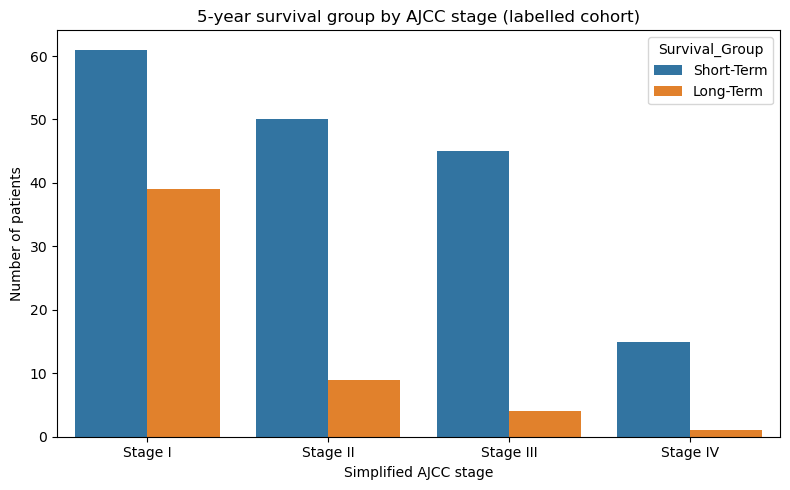

,Stage_Simplified,Long-Term proportion
0,Stage I,0.390000
1,Stage II,0.152542
2,Stage III,0.081633
3,Stage IV,0.062500


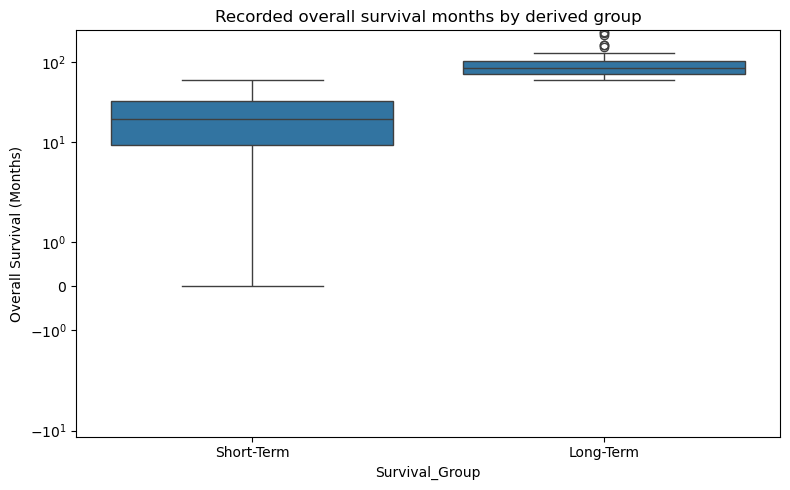

In [24]:
# Function to simplify stage names (e.g., "STAGE IA", "STAGE IIIB" -> "Stage I", "Stage III")
def simplify_stage(value):
    if pd.isna(value):
        return np.nan
    s = str(value).upper().replace(" ", "")
    m = re.search(r"STAGE(IV|III|II|I)", s)
    if not m:
        return np.nan
    return "Stage " + m.group(1)
    
# Apply the function to the stage column
model_df["Stage_Simplified"] = model_df[STAGE_COL].apply(simplify_stage)

# Display the distribution of patients across simplified stages
print("Stage distribution:")
display(model_df["Stage_Simplified"].value_counts(dropna=False).to_frame("patients"))

# Bar chart: Number of Long-Term vs Short-Term patients within each stage
plt.figure(figsize=(8,5))
sns.countplot(data=model_df, x="Stage_Simplified", hue="Survival_Group",
              order=["Stage I","Stage II","Stage III","Stage IV"])
plt.title("5-year survival group by AJCC stage (labelled cohort)")
plt.xlabel("Simplified AJCC stage"); plt.ylabel("Number of patients")
plt.tight_layout(); plt.show()

# Calculate Long-Term survival proportion for each stage
stage_rates = model_df.groupby("Stage_Simplified", dropna=False)["Survival_Group"].apply(
    lambda s: (s == "Long-Term").mean()).rename("Long-Term proportion").reset_index()
display(stage_rates)

# Boxplot: Distribution of survival months for Long-Term vs Short-Term groups
plt.figure(figsize=(8,5))
sns.boxplot(data=model_df, x="Survival_Group", y=OS_COL)
plt.yscale("symlog")
plt.title("Recorded overall survival months by derived group")
plt.tight_layout(); plt.show()

## 4. Predictors and leakage-safe split
The selected inputs are available as candidate diagnosis-time variables. We exclude patient identifiers and all outcome-derived/post-outcome fields, including overall survival months/status, disease-specific survival, progression-free survival, follow-up dates and event status fields.

A stratified holdout test set is kept untouched. Imputation, scaling, and one-hot encoding are fitted only on training folds via pipelines.

In [25]:
# Define the list of selected features (predictors) to be used for modeling
FEATURES = [
    "Diagnosis Age", "Sex", "Radiation Therapy", "Mutation Count",
    "Fraction Genome Altered", "Stage_Simplified"
]

# Check if any required feature columns are missing from the dataset
missing_features = [c for c in FEATURES if c not in model_df.columns]
if missing_features:
    raise ValueError(f"Missing required feature columns: {missing_features}")

# Separate the predictors (X) and the target variable (y)
X = model_df[FEATURES].copy()
y = model_df["Survival_Group"].copy()

# Define numeric and categorical features for separate preprocessing
# Note: Radiation Therapy may contain missing values, which will be handled inside the pipeline.
numeric_features = ["Diagnosis Age", "Mutation Count", "Fraction Genome Altered"]
categorical_features = ["Sex", "Radiation Therapy", "Stage_Simplified"]

# Perform a stratified train-test split (80% train, 20% test) to maintain class distribution
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

# Display the shapes of the training and testing sets
print("Train:", X_train.shape, " Test:", X_test.shape)

# Display class distribution in the training set
print("Train distribution:"); display(y_train.value_counts())

# Display class distribution in the test set
print("Test distribution:"); display(y_test.value_counts())

Train: (179, 6)  Test: (45, 6)
Train distribution:


Survival_Group
Short-Term    137
Long-Term      42
Name: count, dtype: int64

Test distribution:


Survival_Group
Short-Term    34
Long-Term     11
Name: count, dtype: int64

## 5. Baseline model comparison
Macro-F1 and Long-Term recall are reported alongside accuracy because accuracy can hide poor minority-class detection. The baseline models use class weights where supported.

In [26]:
# Create a pipeline for numerical features: impute missing values with median, then standardize
numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Create a pipeline for categorical features: impute missing values with most frequent, then one-hot encode
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both pipelines into a ColumnTransformer
preprocessor = ColumnTransformer([
    ("num", numeric_pipe, numeric_features),
    ("cat", categorical_pipe, categorical_features)
])

# Define four baseline models with class weights where supported to handle class imbalance
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(n_neighbors=7),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=5,
                                              class_weight="balanced_subsample",
                                              random_state=RANDOM_STATE)
}

# Initialize lists to store results and fitted models
results = []
fitted_models = {}

# Loop through each model, train it using the pipeline, and evaluate on the test set
for name, estimator in models.items():
    # Create a full pipeline with preprocessing and the model
    pipe = Pipeline([("preprocessor", preprocessor), ("model", estimator)])
    
    # Fit the pipeline on training data
    pipe.fit(X_train, y_train)

     # Predict on the test set
    pred = pipe.predict(X_test)

    # Calculate and store evaluation metrics
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Macro-F1": f1_score(y_test, pred, average="macro", zero_division=0),
        "Long-Term Recall": recall_score(y_test, pred, pos_label="Long-Term", zero_division=0)
    })

    # Store the fitted pipeline for later use (e.g., SHAP or deployment)
    fitted_models[name] = pipe

# Create a comparison table and sort by Macro-F1 score
comparison = pd.DataFrame(results).sort_values("Macro-F1", ascending=False)

# Display the comparison table
display(comparison)

,Model,Accuracy,Macro-F1,Long-Term Recall
1,Decision Tree,0.733333,0.675481,0.636364
2,KNN,0.733333,0.614286,0.363636
3,Random Forest,0.688889,0.602273,0.454545
0,Logistic Regression,0.622222,0.567552,0.545455


## 6. Stratified cross-validation
Cross-validation is performed on the training set only. It provides a stability estimate without using the holdout test set for model selection.

In [27]:
# Initialize 5-fold Stratified K-Fold cross-validation
# Stratified ensures each fold maintains the same class distribution as the original dataset
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Create an empty list to store cross-validation results for each model
cv_rows = []

# Loop through each model to evaluate its stability using cross-validation
for name, estimator in models.items():

    # Build a pipeline with preprocessing and the model (re-created for each model to avoid data leakage)
    pipe = Pipeline([("preprocessor", preprocessor), ("model", estimator)])

    # Run cross-validation on the TRAINING set only (test set remains untouched for final evaluation)
    # scoring: evaluate both macro F1 and accuracy for a balanced view of performance
    scores = cross_validate(pipe, X_train, y_train, cv=cv,
                            scoring={"macro_f1":"f1_macro", "accuracy":"accuracy"},
                            n_jobs=-1) # n_jobs=-1 uses all CPU cores for parallel processing

    # Store the mean and standard deviation of cross-validation scores for comparison
    cv_rows.append({"Model":name,
                    "CV Macro-F1 mean":scores["test_macro_f1"].mean(),
                    "CV Macro-F1 std":scores["test_macro_f1"].std(),
                    "CV Accuracy mean":scores["test_accuracy"].mean()})

# Create a DataFrame to display the CV comparison results, sorted by Macro-F1 (descending)    
cv_table = pd.DataFrame(cv_rows).sort_values("CV Macro-F1 mean", ascending=False)

# Display the final cross-validation comparison table
display(cv_table)

,Model,CV Macro-F1 mean,CV Macro-F1 std,CV Accuracy mean
1,Decision Tree,0.643180,0.065361,0.703810
3,Random Forest,0.629195,0.122569,0.720159
0,Logistic Regression,0.618516,0.022664,0.664921
2,KNN,0.575362,0.038518,0.731746


## 7. SMOTENC experiment (training data only)
Because the raw predictors mix numeric and categorical variables, SMOTENC is used rather than ordinary SMOTE on one-hot encoded dummy variables. Imputation is learned on training data only; the resampler is inside an imbalanced-learn pipeline, so it is applied only during fitting and never to the test set.

If the minority class is too small for the default neighbour count, the code adapts `k_neighbors`. The test set remains unchanged.

In [28]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTENC

# Step 1: Pre-SMOTE Preprocessing
# Impute missing values while preserving categorical columns (no encoding yet).
# Output order: numeric features first, then categorical features.
pre_smote = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_features),
    ("cat", SimpleImputer(strategy="most_frequent"), categorical_features)
], verbose_feature_names_out=False)

# Step 2: SMOTENC expects categorical feature positions in the transformed matrix
# These are the indices of the categorical columns (after numeric columns)
cat_positions = list(range(len(numeric_features), len(numeric_features)+len(categorical_features)))

# Step 3: Post-SMOTE Processing
# After SMOTE generates synthetic data, scale numeric features and one-hot encode categorical features.
post_smote = ColumnTransformer([
    ("num", StandardScaler(), list(range(len(numeric_features)))),
    ("cat", OneHotEncoder(handle_unknown="ignore"),
     list(range(len(numeric_features), len(numeric_features)+len(categorical_features))))
])


# Step 4: Adapt k_neighbors for small minority class
# SMOTENC requires at least k_neighbors samples in the minority class
minority_n = int(y_train.value_counts().min())
k = max(1, min(5, minority_n - 1))

# Step 5: Full Imbalanced-Learn Pipeline
# SMOTENC is applied ONLY during fitting (training), never to the test set.
smote_model = ImbPipeline([
    ("impute", pre_smote),
    ("smotenc", SMOTENC(categorical_features=cat_positions, random_state=RANDOM_STATE,
                        k_neighbors=k)),
    ("encode_scale", post_smote),
    ("model", RandomForestClassifier(n_estimators=300, max_depth=5,
                                     random_state=RANDOM_STATE))
])

# Train the SMOTE-augmented pipeline
smote_model.fit(X_train, y_train)

# Predict on the untouched test set
smote_pred = smote_model.predict(X_test)

# Step 6: Evaluate SMOTENC model
smote_result = {
    "Model":"Random Forest + SMOTENC",
    "Accuracy":accuracy_score(y_test, smote_pred),
    "Macro-F1":f1_score(y_test, smote_pred, average="macro", zero_division=0),
    "Long-Term Recall":recall_score(y_test, smote_pred, pos_label="Long-Term", zero_division=0)
}
display(pd.DataFrame([smote_result]))

# Step 7: Diagnostic check (before and after SMOTENC)
print("Training class counts before resampling:")
display(y_train.value_counts())
print("Training class counts after SMOTENC (fit_resample diagnostic):")
Xt_imp = pre_smote.fit_transform(X_train)
_, yt_bal = SMOTENC(categorical_features=cat_positions, random_state=RANDOM_STATE,
                    k_neighbors=k).fit_resample(Xt_imp, y_train)
display(pd.Series(yt_bal).value_counts())

,Model,Accuracy,Macro-F1,Long-Term Recall
0,Random Forest + SMOTENC,0.688889,0.621394,0.545455


Training class counts before resampling:


Survival_Group
Short-Term    137
Long-Term      42
Name: count, dtype: int64

Training class counts after SMOTENC (fit_resample diagnostic):


Survival_Group
Long-Term     137
Short-Term    137
Name: count, dtype: int64

## 8. Holdout error analysis
The confusion matrix and per-class report make minority-class errors visible. Interpret Long-Term recall carefully because the Long-Term group is relatively small.

Selected baseline by training CV Macro-F1: Decision Tree
              precision    recall  f1-score   support

   Long-Term       0.47      0.64      0.54        11
  Short-Term       0.87      0.76      0.81        34

    accuracy                           0.73        45
   macro avg       0.67      0.70      0.68        45
weighted avg       0.77      0.73      0.75        45



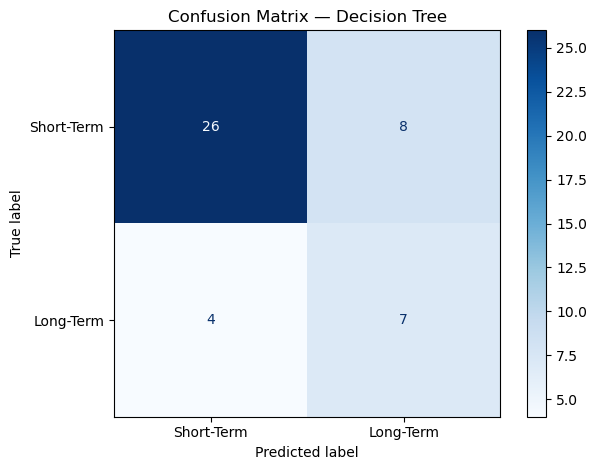

,Model,Accuracy,Macro-F1,Long-Term Recall
0,Decision Tree,0.733333,0.675481,0.636364
4,Random Forest + SMOTENC,0.688889,0.621394,0.545455
1,KNN,0.733333,0.614286,0.363636
2,Random Forest,0.688889,0.602273,0.454545
3,Logistic Regression,0.622222,0.567552,0.545455


In [29]:
# Select the best model based on training-only CV Macro-F1 (not holdout test performance)
# This prevents selecting a model that simply got lucky on the test set
best_name = cv_table.iloc[0]["Model"]

# Retrieve the fitted pipeline for the best model
best_pipeline = fitted_models[best_name]

# Predict on the untouched holdout test set for final evaluation
best_pred = best_pipeline.predict(X_test)

# Print the selected model and detailed per-class classification report
print("Selected baseline by training CV Macro-F1:", best_name)
print(classification_report(y_test, best_pred, zero_division=0))

# Compute and visualize the confusion matrix
# Labels are ordered as Short-Term then Long-Term for clarity
cm = confusion_matrix(y_test, best_pred, labels=["Short-Term","Long-Term"])
ConfusionMatrixDisplay(cm, display_labels=["Short-Term","Long-Term"]).plot(cmap="Blues")
plt.title(f"Confusion Matrix — {best_name}")
plt.tight_layout(); plt.show()

# Combine baseline models and SMOTENC experiment results into a single comparison table
final_comparison = pd.concat([
    comparison,  # Results from baseline models
    pd.DataFrame([smote_result])  # Results from SMOTENC experiment
], ignore_index=True).sort_values("Macro-F1", ascending=False)

# Display final model comparison
display(final_comparison)

# Save the final comparison table as a CSV file for the report and GitHub repository
final_comparison.to_csv("assignment6_model_comparison.csv", index=False)

## 9. Save the complete deployment pipeline
The saved object includes all preprocessing steps and the classifier. The Streamlit app must use the same six input columns in the same names.

In [30]:
# Select the best-performing baseline pipeline (based on holdout Macro-F1) for deployment
# This pipeline is used in the Streamlit web application
deployment_pipeline = fitted_models[best_name]

# Save the complete pipeline (preprocessing + model) as a single file using joblib
# Saving the entire pipeline ensures that the Streamlit app uses the exact same preprocessing steps
# (imputation, scaling, encoding) that were used during training
joblib.dump(deployment_pipeline, "lung_cancer_survival_pipeline.joblib")

# Confirm the file was saved successfully
print("Saved: lung_cancer_survival_pipeline.joblib")

# Print the exact feature order that the Streamlit app must follow
# The app must provide these six columns in this same order for correct predictions
print("Deployment feature order:", FEATURES)

Saved: lung_cancer_survival_pipeline.joblib
Deployment feature order: ['Diagnosis Age', 'Sex', 'Radiation Therapy', 'Mutation Count', 'Fraction Genome Altered', 'Stage_Simplified']


## 10. Business-facing interpretation and limitations
- Classification, not Survival Analysis: This model predicts a 60-month binary outcome (Long-Term vs. Short-Term). It does not calculate exact time-to-event like a Cox regression model.

- Censored Data: Patients alive with less than 60 months of follow-up were excluded because their final 5-year outcome is unknown.

- Small and Imbalanced Data: The dataset is small and imbalanced. Model results can change significantly depending on the train-test split.

- Experimental Methods: Class weights and SMOTENC were used to handle imbalance. These are experiments, not proof of clinical benefit.

- Temporal Leakage Risk: "Radiation Therapy" may be decided after diagnosis. For a true diagnosis-time tool, this could introduce temporal leakage.

- Educational Only: This prototype is for educational purposes and should not be used for real clinical decisions.

- Future Work: Before any real-world use, the model needs external validation, fairness checks, and prospective testing.